# Experiment 15:- Write a Program to Implement Principal Component Analysis (PCA)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [3]:
dataset = load_digits()

X = dataset.data
y = dataset.target

print("Dataset loaded successfully")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully
Features shape: (1797, 64)
Target shape: (1797,)


In [4]:
df = pd.DataFrame(X, columns=dataset.feature_names)

df.head()

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


In [5]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Description:")
print(df.describe())

print("\nOriginal Dataset Shape:", X.shape)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1797 entries, 0 to 1796
Data columns (total 64 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pixel_0_0  1797 non-null   float64
 1   pixel_0_1  1797 non-null   float64
 2   pixel_0_2  1797 non-null   float64
 3   pixel_0_3  1797 non-null   float64
 4   pixel_0_4  1797 non-null   float64
 5   pixel_0_5  1797 non-null   float64
 6   pixel_0_6  1797 non-null   float64
 7   pixel_0_7  1797 non-null   float64
 8   pixel_1_0  1797 non-null   float64
 9   pixel_1_1  1797 non-null   float64
 10  pixel_1_2  1797 non-null   float64
 11  pixel_1_3  1797 non-null   float64
 12  pixel_1_4  1797 non-null   float64
 13  pixel_1_5  1797 non-null   float64
 14  pixel_1_6  1797 non-null   float64
 15  pixel_1_7  1797 non-null   float64
 16  pixel_2_0  1797 non-null   float64
 17  pixel_2_1  1797 non-null   float64
 18  pixel_2_2  1797 non-null   float64
 19  pixel_2_3  1797 non-null   float64
 20

       pixel_0_0    pixel_0_1    pixel_0_2    pixel_0_3    pixel_0_4  \
count     1797.0  1797.000000  1797.000000  1797.000000  1797.000000   
mean         0.0     0.303840     5.204786    11.835838    11.848080   
std          0.0     0.907192     4.754826     4.248842     4.287388   
min          0.0     0.000000     0.000000     0.000000     0.000000   
25%          0.0     0.000000     1.000000    10.000000    10.000000   
50%          0.0     0.000000     4.000000    13.000000    13.000000   
75%          0.0     0.000000     9.000000    15.000000    15.000000   
max          0.0     8.000000    16.000000    16.000000    16.000000   

         pixel_0_5    pixel_0_6    pixel_0_7    pixel_1_0    pixel_1_1  ...  \
count  1797.000000  1797.000000  1797.000000  1797.000000  1797.000000  ...   
mean      5.781859     1.362270     0.129661     0.005565     1.993879  ...   
std       5.666418     3.325775     1.037383     0.094222     3.196160  ...   
min       0.000000     0.000000    

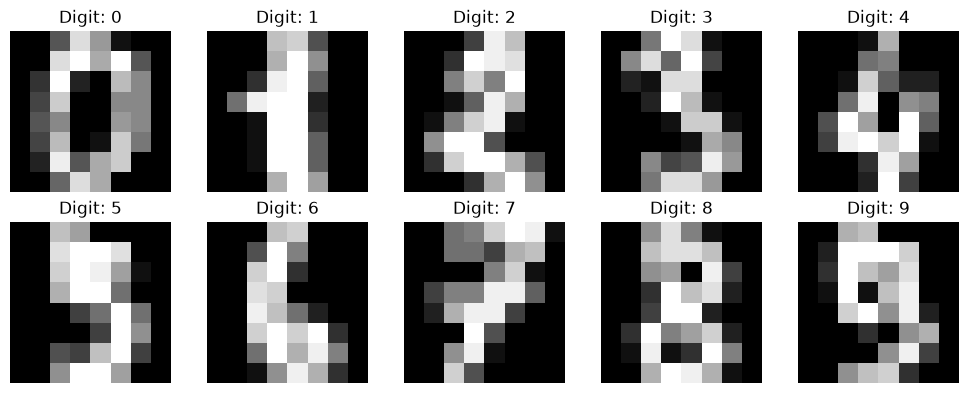

In [6]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(dataset.images[i], cmap="gray")
    plt.title(f"Digit: {y[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized Data Shape:", X_scaled.shape)

Standardized Data Shape: (1797, 64)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1437, 64)
Testing Data: (360, 64)


In [9]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy without PCA:", accuracy)

Accuracy without PCA: 0.9722222222222222


In [10]:
pca = PCA(n_components=0.97)

X_pca = pca.fit_transform(X_scaled)

print("Original Features:", X.shape[1])
print("Features after PCA:", X_pca.shape[1])
print("Transformed Data Shape:", X_pca.shape)

Original Features: 64
Features after PCA: 46
Transformed Data Shape: (1797, 46)


In [11]:
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data after PCA:", X_train_pca.shape)
print("Testing Data after PCA:", X_test_pca.shape)

Training Data after PCA: (1437, 46)
Testing Data after PCA: (360, 46)


In [12]:
model_pca = LogisticRegression(max_iter=1000)

model_pca.fit(X_train_pca, y_train_pca)

y_pred_pca = model_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(y_test_pca, y_pred_pca)

print("Accuracy with PCA:", accuracy_pca)

Accuracy with PCA: 0.9666666666666667


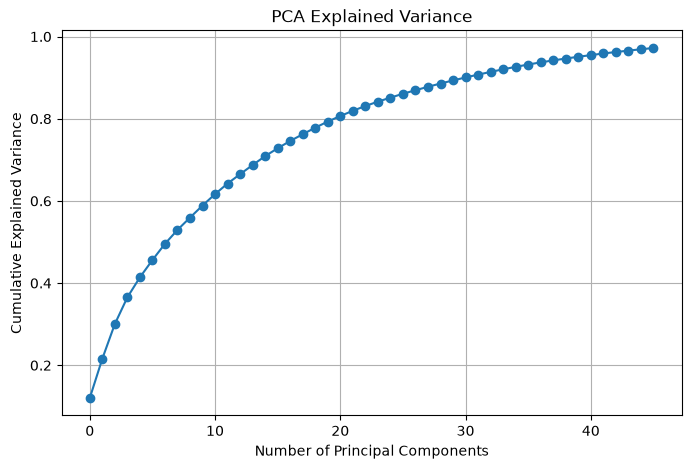

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    np.cumsum(pca.explained_variance_ratio_),
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")

plt.grid(True)
plt.show()

In [14]:
print("----- FINAL RESULTS -----")
print("Original Number of Features:", X.shape[1])
print("Features after PCA:", X_pca.shape[1])
print("Accuracy without PCA:", round(accuracy * 100, 2), "%")
print("Accuracy with PCA:", round(accuracy_pca * 100, 2), "%")
print("Variance Retained:", round(
    np.sum(pca.explained_variance_ratio_) * 100, 2
), "%")

----- FINAL RESULTS -----
Original Number of Features: 64
Features after PCA: 46
Accuracy without PCA: 97.22 %
Accuracy with PCA: 96.67 %
Variance Retained: 97.22 %
